# 🛰️ Monitoreo de Salud de Naves Espaciales con Modelos Ocultos de Markov (HMM)
### Suite Completa: Simulación Orbital, Inferencia Viterbi, Grafos NetworkX, Monte Carlo y Baum-Welch

Este notebook integra todas las capacidades de modelado estocástico aplicadas a telemetría aeroespacial:
1. **Modelo HMM completo** (Viterbi logarítmico y Forward filtering).
2. **Visualizaciones de sala de control:** Línea de tiempo, latidos RF (Heartbeat) y semáforo de vuelo.
3. **Grafos de Arquitectura con NetworkX:** Diagramas dirigidos de transición y emisión estocástica.
4. **Simulación Masiva Monte Carlo ($N = 10{,}000$ misiones):** Curva de fiabilidad $R(t)$ y tiempo medio a la falla (MTTF).
5. **Algoritmo de Baum-Welch (EM):** Calibración no supervisada de matrices a partir de telemetría en bruto.
6. **Monitor de Telemetría en Streaming:** Procesador en tiempo real para detección temprana y activación de Safe-Hold Mode.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## 1. Configuración del Entorno
El código utiliza `numpy`, `matplotlib` y `networkx`.

In [1]:
%pip install numpy matplotlib networkx
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
import networkx as nx
from typing import List, Tuple, Dict, Any

plt.style.use('dark_background')
print("✓ Entorno aeroespacial inicializado con éxito.")

Note: you may need to restart the kernel to use updated packages.
✓ Entorno aeroespacial inicializado con éxito.


## 2. Definición del Modelo `SpacecraftHMM` (Viterbi & Forward)

In [2]:
class SpacecraftHMM:
    STATE_NAMES = ['Operación Nominal', 'Degradación de Sistemas', 'Anomalía Crítica']
    STATE_COLORS = ['#00E676', '#FFD600', '#FF1744']
    OBS_NAMES = ['Señal Estable', 'Señal Intermitente', 'Señal Perdida']

    def __init__(self, transition_matrix=None, emission_matrix=None, initial_distribution=None):
        self.A = np.array(transition_matrix if transition_matrix is not None else [
            [0.90, 0.08, 0.02],
            [0.40, 0.45, 0.15],
            [0.05, 0.15, 0.80]
        ], dtype=np.float64)

        self.B = np.array(emission_matrix if emission_matrix is not None else [
            [0.85, 0.12, 0.03],
            [0.30, 0.50, 0.20],
            [0.05, 0.15, 0.80]
        ], dtype=np.float64)

        self.pi = np.array(initial_distribution if initial_distribution is not None else [
            0.85, 0.10, 0.05
        ], dtype=np.float64)

        self.n_states = len(self.STATE_NAMES)
        self.n_obs = len(self.OBS_NAMES)

    def simulate(self, n_hours: int = 72, seed: int = 42) -> Tuple[np.ndarray, np.ndarray]:
        rng = np.random.default_rng(seed)
        states = np.zeros(n_hours, dtype=int)
        observations = np.zeros(n_hours, dtype=int)

        states[0] = rng.choice(self.n_states, p=self.pi)
        observations[0] = rng.choice(self.n_obs, p=self.B[states[0]])

        for t in range(1, n_hours):
            states[t] = rng.choice(self.n_states, p=self.A[states[t - 1]])
            observations[t] = rng.choice(self.n_obs, p=self.B[states[t]])

        return states, observations

    def viterbi(self, observations: np.ndarray) -> Tuple[np.ndarray, float]:
        T = len(observations)
        K = self.n_states
        eps = 1e-16

        log_pi = np.log(self.pi + eps)
        log_A = np.log(self.A + eps)
        log_B = np.log(self.B + eps)

        V = np.zeros((T, K), dtype=np.float64)
        backpointer = np.zeros((T, K), dtype=int)

        V[0, :] = log_pi + log_B[:, observations[0]]

        for t in range(1, T):
            obs = observations[t]
            for j in range(K):
                candidates = V[t - 1, :] + log_A[:, j]
                best_prev = np.argmax(candidates)
                backpointer[t, j] = best_prev
                V[t, j] = candidates[best_prev] + log_B[j, obs]

        best_last = np.argmax(V[T - 1, :])
        best_log_prob = V[T - 1, best_last]

        best_path = np.zeros(T, dtype=int)
        best_path[T - 1] = best_last
        for t in range(T - 2, -1, -1):
            best_path[t] = backpointer[t + 1, best_path[t + 1]]

        return best_path, float(best_log_prob)

    def forward_filtering(self, observations: np.ndarray) -> np.ndarray:
        T = len(observations)
        K = self.n_states
        alpha = np.zeros((T, K), dtype=np.float64)

        raw = self.pi * self.B[:, observations[0]]
        alpha[0, :] = raw / np.sum(raw)

        for t in range(1, T):
            prior = alpha[t - 1, :] @ self.A
            raw = prior * self.B[:, observations[t]]
            scale = np.sum(raw)
            alpha[t, :] = raw / (scale if scale > 0 else 1.0)

        return alpha

    def compute_steady_state(self) -> np.ndarray:
        K = self.n_states
        M = self.A.T - np.eye(K)
        M[-1, :] = 1.0
        rhs = np.zeros(K)
        rhs[-1] = 1.0
        try:
            return np.clip(np.linalg.solve(M, rhs), 0, 1)
        except np.linalg.LinAlgError:
            return np.linalg.matrix_power(self.A, 500)[0, :]

    def risk_profile_projection(self, n_steps: int = 72) -> np.ndarray:
        evolution = np.zeros((n_steps, self.n_states))
        current = self.pi.copy()
        for t in range(n_steps):
            evolution[t, :] = current
            current = current @ self.A
        return evolution

## 3. Protocolos de Contingencia y KPIs de Telemetría

In [3]:
CONTINGENCY_ACTIONS = {
    0: {
        "estado": "Operación Nominal",
        "semaforo": "VERDE",
        "codigo": "STATUS-GREEN // NOMINAL FLIGHT",
        "color": "#00E676",
        "directiva": "CONTINUAR MISIÓN NOMINAL",
        "procedimientos": [
            "Mantener cronograma de ciencia y telemetría de alta velocidad (Banda X).",
            "Cargas útiles científicas al 100% de potencia nominal.",
            "Monitoreo estándar de ciclo térmico y orientación de paneles solares.",
            "Descarga de buffers de memoria de a bordo programada en el próximo pase."
        ]
    },
    1: {
        "estado": "Degradación de Sistemas",
        "semaforo": "AMARILLO",
        "codigo": "STATUS-AMBER // SYSTEM DEGRADATION",
        "color": "#FFD600",
        "directiva": "MONITOREO INTENSIVO Y DIAGNÓSTICO",
        "procedimientos": [
            "Activar telemetría de ingeniería de alta resolución (sub-rate 1 Hz).",
            "Suspender maniobras orbitales y experimentos científicos no críticos.",
            "Aislar bus de carga útil secundaria; verificar márgenes de potencia.",
            "Ejecutar diagnóstico térmico de tubos amplificadores de potencia (TWTA).",
            "Preparar comandos de conmutación a cadena de aviónica redundante (Canal B)."
        ]
    },
    2: {
        "estado": "Anomalía Crítica",
        "semaforo": "ROJO",
        "codigo": "STATUS-RED // CRITICAL FAULT - SAFE HOLD",
        "color": "#FF1744",
        "directiva": "ACTIVAR MODO SEGURO (SAFE-HOLD MODE)",
        "procedimientos": [
            "ORDEN INMEDIATA: Disparar rutina de aborto y modo de supervivencia.",
            "Apagado total de todas las cargas útiles e instrumentos científicos.",
            "Orientar eje primario de paneles solares directamente hacia el vector Sol.",
            "Conmutar transmisor a Antena de Baja Ganancia (LGA) omnidireccional en Banda S.",
            "Amortiguamiento de giros de actitud con ruedas de reacción y propulsores RCS.",
            "Notificar a la Red del Espacio Profundo (DSN) para enlace de emergencia continuo."
        ]
    }
}

def compute_mission_kpis(real_states, observations, viterbi_states):
    T = len(real_states)
    stable_h = int(np.sum(observations == 0))
    intermittent_h = int(np.sum(observations == 1))
    lost_h = int(np.sum(observations == 2))
    availability = (stable_h / T) * 100.0
    real_counts = [int(np.sum(real_states == s)) for s in range(3)]
    viterbi_counts = [int(np.sum(viterbi_states == s)) for s in range(3)]

    los_runs, current_run = [], 0
    for obs in observations:
        if obs == 2:
            current_run += 1
        else:
            if current_run > 0:
                los_runs.append(current_run)
                current_run = 0
    if current_run > 0: los_runs.append(current_run)

    delays = []
    in_fault = False
    start_t = 0
    for t in range(T):
        fault_active = (real_states[t] in [1, 2])
        if fault_active and not in_fault:
            in_fault = True
            start_t = t
            detected = next((scan for scan in range(start_t, T) if viterbi_states[scan] in [1, 2]), T)
            delays.append(detected - start_t)
        elif not fault_active and in_fault:
            in_fault = False

    conf = np.zeros((3, 3), dtype=int)
    for r, v in zip(real_states, viterbi_states): conf[r, v] += 1
    accuracy = float(np.trace(conf) / T) * 100.0

    return {
        "total_hours": T,
        "availability_pct": availability,
        "stable_hours": stable_h,
        "intermittent_hours": intermittent_h,
        "lost_hours": lost_h,
        "real_counts": real_counts,
        "viterbi_counts": viterbi_counts,
        "los_runs": los_runs,
        "max_los_hours": max(los_runs) if los_runs else 0,
        "mean_los_hours": float(np.mean(los_runs)) if los_runs else 0.0,
        "avg_detection_delay": float(np.mean(delays)) if delays else 0.0,
        "max_detection_delay": int(np.max(delays)) if delays else 0,
        "confusion_matrix": conf,
        "accuracy": accuracy
    }

def generate_heartbeat_signal(observations, samples_per_hour=40):
    T = len(observations)
    n_samples = T * samples_per_hour
    t_axis = np.linspace(0, T, n_samples, endpoint=False)
    signal = np.zeros(n_samples)
    rng = np.random.default_rng(777)

    for h in range(T):
        i0, i1 = h * samples_per_hour, (h + 1) * samples_per_hour
        tau = t_axis[i0:i1] - h
        pulse = np.exp(-((tau - 0.25) ** 2) / 0.008) * 1.4 - np.exp(-((tau - 0.35) ** 2) / 0.004) * 0.7
        obs = observations[h]
        if obs == 0:
            signal[i0:i1] = pulse + 0.25 * np.cos(2 * np.pi * 12 * tau) + rng.normal(0, 0.04, samples_per_hour)
        elif obs == 1:
            drop = rng.choice([0.0, 1.0], size=samples_per_hour, p=[0.3, 0.7])
            signal[i0:i1] = (pulse * drop * rng.uniform(0.3, 0.6, samples_per_hour)) + rng.normal(0, 0.12, samples_per_hour)
        else:
            signal[i0:i1] = rng.normal(0, 0.06, samples_per_hour)

    return t_axis, signal

## 4. Visualización 1: Telemetría 72h, Alertas y Latidos RF

In [4]:
def plot_timeline_and_heartbeat(real_states, observations, viterbi_states, alpha_probs):
    fig = plt.figure(figsize=(16, 13), facecolor='#0B0F19')
    gs = GridSpec(4, 1, height_ratios=[2.2, 1.3, 1.4, 1.3], hspace=0.35)
    hours = np.arange(len(real_states))
    colors = SpacecraftHMM.STATE_COLORS

    # Subplot 0: Observaciones con fondo de salud real
    ax0 = fig.add_subplot(gs[0])
    ax0.set_facecolor('#101626')
    ax0.set_title("✦ TELEMETRÍA DE TIERRA, ESTADOS DE SALUD REAL Y ALERTAS CRÍTICAS (72 HORAS MET) ✦", 
                  fontsize=12, fontweight='bold', color='#E0E6ED', pad=12)
    for t in range(len(real_states)):
        ax0.axvspan(t - 0.5, t + 0.5, color=colors[real_states[t]], alpha=0.18, zorder=0)
    obs_y = np.array([{0: 2, 1: 1, 2: 0}[o] for o in observations])
    ax0.step(hours, obs_y, where='mid', color='#00E5FF', lw=2.0, label='Calidad de Señal Recibida (Tierra)', zorder=2)
    ax0.scatter(hours[observations == 0], obs_y[observations == 0], marker='o', color='#00E676', s=60, label='Señal Estable', zorder=3)
    ax0.scatter(hours[observations == 1], obs_y[observations == 1], marker='^', color='#FFD600', s=70, label='Señal Intermitente', zorder=3)
    ax0.scatter(hours[observations == 2], obs_y[observations == 2], marker='X', color='#FF1744', s=80, label='Señal Perdida (LOS)', zorder=3)

    for t in range(len(real_states)):
        if real_states[t] == 2:
            ax0.scatter(t, 2.3, marker='v', color='#FF1744', s=120, zorder=5)
            if t == 0 or real_states[t - 1] != 2:
                ax0.annotate(f"¡ANOMALÍA!\nT+{t:02d}h", xy=(t, 2.3), xytext=(t, 2.7),
                             arrowprops=dict(facecolor='#FF1744', edgecolor='#FFFFFF', arrowstyle="->", lw=1.2),
                             fontsize=8, fontweight='bold', color='#FF5252', ha='center',
                             bbox=dict(boxstyle="round,pad=0.2", fc="#2A0B14", ec="#FF1744", lw=1.2))
    ax0.set_yticks([0, 1, 2]); ax0.set_yticklabels(['Perdida', 'Intermitente', 'Estable'], fontsize=10, fontweight='bold')
    ax0.set_ylim(-0.5, 3.1); ax0.grid(True, linestyle=':', alpha=0.3, color='#455A64')
    ax0.legend(loc='upper right', ncol=3, fontsize=8, facecolor='#161F33', edgecolor='#37474F')

    # Subplot 1: Real vs Viterbi
    ax1 = fig.add_subplot(gs[1], sharex=ax0)
    ax1.set_facecolor('#101626')
    ax1.set_title("DIAGNÓSTICO INFERIDO: ESTADO REAL (NAVE) VS ALGORITMO DE VITERBI (TIERRA)", fontsize=10, fontweight='bold', color='#90CAF9', loc='left')
    ax1.plot(hours, real_states, color='#76FF03', lw=2.4, label='Salud Real (Ground Truth)')
    ax1.step(hours, viterbi_states, where='mid', color='#FF4081', lw=2.0, linestyle='--', label='Inferencia Viterbi')
    ax1.set_yticks([0, 1, 2]); ax1.set_yticklabels(['Nominal', 'Degradación', 'Crítica'], fontsize=9)
    ax1.grid(True, linestyle=':', alpha=0.3, color='#455A64')
    ax1.legend(loc='upper right', fontsize=8, facecolor='#161F33', edgecolor='#37474F')

    # Subplot 2: Forward probabilities
    ax2 = fig.add_subplot(gs[2], sharex=ax0)
    ax2.set_facecolor('#101626')
    ax2.set_title("PROBABILIDAD POSTERIOR EN TIEMPO REAL: P(S_t | O_1:t) - ESTIMACIÓN DE CONTROL DE VUELO", fontsize=10, fontweight='bold', color='#90CAF9', loc='left')
    ax2.plot(hours, alpha_probs[:, 0], color=colors[0], lw=1.8, label='P(Nominal)')
    ax2.plot(hours, alpha_probs[:, 1], color=colors[1], lw=1.8, label='P(Degradación)')
    ax2.plot(hours, alpha_probs[:, 2], color=colors[2], lw=2.2, label='P(Anomalía Crítica)')
    ax2.fill_between(hours, 0, alpha_probs[:, 2], color=colors[2], alpha=0.22)
    ax2.set_ylim(-0.05, 1.05); ax2.grid(True, linestyle=':', alpha=0.3, color='#455A64')
    ax2.legend(loc='upper right', fontsize=8, facecolor='#161F33', edgecolor='#37474F')

    # Subplot 3: Latidos RF
    ax3 = fig.add_subplot(gs[3], sharex=ax0)
    ax3.set_facecolor('#0A0E1A')
    ax3.set_title("FORMA DE ONDA DE LATIDOS (HEARTBEAT CARRIER WAVEFORM - BALIZA DE RF)", fontsize=10, fontweight='bold', color='#00E5FF', loc='left')
    t_wave, waveform = generate_heartbeat_signal(observations)
    ax3.plot(t_wave, waveform, color='#00E5FF', lw=0.9, alpha=0.9)
    ax3.set_xlabel("Tiempo Transcurrido de Misión (Horas MET)", fontsize=11, fontweight='bold', color='#E0E6ED')
    ax3.set_xlim(-0.5, len(real_states) - 0.5)
    ax3.set_xticks(np.arange(0, len(real_states) + 1, 6))
    ax3.grid(True, linestyle=':', alpha=0.3, color='#455A64')

    plt.tight_layout()
    plt.show()

## 5. Visualización 2: Dashboard de Control de Misión con Semáforo y KPIs

In [5]:
def plot_mission_dashboard(metrics, active_state, steady_state, risk_curve):
    fig = plt.figure(figsize=(18, 11), facecolor='#080C14')
    gs = GridSpec(2, 3, width_ratios=[1.1, 1.0, 1.2], height_ratios=[1.0, 1.0], wspace=0.28, hspace=0.32)
    proto = CONTINGENCY_ACTIONS[active_state]

    # Semáforo
    ax_light = fig.add_subplot(gs[0, 0])
    ax_light.set_facecolor('#101626')
    ax_light.set_title("✦ SEMÁFORO DE SALUD DE VUELO ✦", fontsize=11, fontweight='bold', color='#90CAF9')
    cuerpo = mpatches.FancyBboxPatch((0.15, -0.2), 0.7, 2.8, boxstyle="round,pad=0.1", ec="#37474F", fc="#0A0E17", lw=2.0)
    ax_light.add_patch(cuerpo)
    lamp_y = [2.2, 1.2, 0.2]
    lamp_colors = ['#00E676', '#FFD600', '#FF1744']
    lamp_names = ['NOMINAL', 'DEGRADACIÓN', 'CRÍTICO']
    for i in range(3):
        active = (i == active_state)
        if active:
            ax_light.add_patch(plt.Circle((0.5, lamp_y[i]), 0.42, color=lamp_colors[i], alpha=0.25, zorder=2))
        circ = plt.Circle((0.5, lamp_y[i]), 0.30, facecolor=lamp_colors[i] if active else '#1E293B',
                          edgecolor=lamp_colors[i] if active else '#334155', lw=2.5, alpha=1.0 if active else 0.3, zorder=3)
        ax_light.add_patch(circ)
        ax_light.text(0.5, lamp_y[i], lamp_names[i], ha='center', va='center', 
                      color='#000000' if active else '#64748B', fontsize=9, fontweight='bold' if active else 'normal', zorder=4)
    ax_light.set_xlim(-0.1, 1.1); ax_light.set_ylim(-0.4, 2.9); ax_light.axis('off')
    ax_light.text(0.5, -0.35, f"STATUS ACTUAL: {proto['semaforo']}", ha='center', va='center', color=proto['color'], fontsize=11, fontweight='bold')

    # Matriz Confusión
    ax_cm = fig.add_subplot(gs[0, 1])
    ax_cm.set_facecolor('#101626')
    ax_cm.set_title("MATRIZ DE CONFUSIÓN (REAL VS VITERBI)", fontsize=11, fontweight='bold', color='#90CAF9')
    cm = metrics["confusion_matrix"]
    cax = ax_cm.imshow(cm, cmap='Blues', alpha=0.85)
    classes = ['Nominal', 'Degrad.', 'Crítica']
    for i in range(3):
        for j in range(3):
            val = cm[i, j]
            ax_cm.text(j, i, f"{val}\n({val/metrics['total_hours']*100:.1f}%)", ha="center", va="center", 
                       color='#FFFFFF' if val > cm.max() / 2 else '#90CAF9', fontsize=10, fontweight='bold')
    ax_cm.set_xticks(range(3)); ax_cm.set_yticks(range(3))
    ax_cm.set_xticklabels(classes); ax_cm.set_yticklabels(classes)
    fig.colorbar(cax, ax=ax_cm, fraction=0.046, pad=0.04)

    # Protocolo Contingencia
    ax_proto = fig.add_subplot(gs[0, 2])
    ax_proto.set_facecolor('#101626')
    ax_proto.set_title(f"DIRECTIVAS Y PLAN DE CONTINGENCIA // {proto['codigo']}", fontsize=10, fontweight='bold', color=proto['color'])
    lines = [f"• ACCIÓN INMEDIATA:\n  {proto['directiva']}\n", "• PROCEDIMIENTOS ESTÁNDAR (SOP):"]
    for step in proto["procedimientos"]: lines.append(f"  [>] {step}")
    ax_proto.text(0.04, 0.92, "\n".join(lines), color='#E2E8F0', fontsize=9.2, verticalalignment='top',
                  fontfamily='monospace', linespacing=1.35,
                  bbox=dict(boxstyle="round,pad=0.7", fc="#0B0F19", ec=proto['color'], lw=1.5))
    ax_proto.axis('off')

    # KPIs
    ax_kpi = fig.add_subplot(gs[1, 1])
    ax_kpi.set_facecolor('#101626')
    ax_kpi.set_title("MÉTRICAS CLAVE DE TELEMETRÍA (KPIS)", fontsize=11, fontweight='bold', color='#90CAF9')
    kpi_text = [
        f"✦ DISPONIBILIDAD TOTAL:      {metrics['availability_pct']:.2f}% ({metrics['stable_hours']}/{metrics['total_hours']}h)",
        f"✦ SEÑAL INTERMITENTE:        {metrics['intermittent_hours']} h ({metrics['intermittent_hours']/metrics['total_hours']*100:.1f}%)",
        f"✦ SEÑAL PERDIDA (LOS):       {metrics['lost_hours']} h ({metrics['lost_hours']/metrics['total_hours']*100:.1f}%)",
        "--------------------------------------------------",
        f"✦ EPISODIOS PÉRDIDA ENLACE:  {len(metrics['los_runs'])} eventos",
        f"✦ DURACIÓN MÁXIMA DE LOS:    {metrics['max_los_hours']} horas seguidas",
        f"✦ DURACIÓN MEDIA DE LOS:     {metrics['mean_los_hours']:.2f} horas",
        "--------------------------------------------------",
        f"✦ PRECISIÓN GLOBAL VITERBI:  {metrics['accuracy']:.2f}%",
        f"✦ RETRASO DETECCIÓN ANOMALÍA: {metrics['avg_detection_delay']:.2f} h (Máx: {metrics['max_detection_delay']}h)"
    ]
    ax_kpi.text(0.04, 0.92, "\n".join(kpi_text), color='#00E5FF', fontsize=9.2, verticalalignment='top',
                fontfamily='monospace', linespacing=1.35,
                bbox=dict(boxstyle="round,pad=0.7", fc="#0B0F19", ec="#00E5FF", lw=1.2))
    ax_kpi.axis('off')

    # Distribución
    ax_dist = fig.add_subplot(gs[1, 0])
    ax_dist.set_facecolor('#101626')
    ax_dist.set_title("DISTRIBUCIÓN TEMPORAL DE SALUD", fontsize=11, fontweight='bold', color='#90CAF9')
    x_bar = np.arange(3); w = 0.35
    r_pct = [c / metrics['total_hours'] * 100 for c in metrics['real_counts']]
    v_pct = [c / metrics['total_hours'] * 100 for c in metrics['viterbi_counts']]
    ax_dist.bar(x_bar - w/2, r_pct, w, label='Real', color=['#00C853', '#FFD600', '#D50000'], alpha=0.85)
    ax_dist.bar(x_bar + w/2, v_pct, w, label='Viterbi', color=['#69F0AE', '#FFE57F', '#FF80AB'], alpha=0.85, hatch='//')
    ax_dist.set_xticks(x_bar); ax_dist.set_xticklabels(classes)
    ax_dist.set_ylabel("% de Misión")
    ax_dist.legend(loc='upper right', fontsize=8, facecolor='#161F33', edgecolor='#37474F')
    ax_dist.grid(True, linestyle=':', alpha=0.3, color='#455A64')

    # Curva Riesgo
    ax_risk = fig.add_subplot(gs[1, 2])
    ax_risk.set_facecolor('#101626')
    ax_risk.set_title("ANÁLISIS DE RIESGO DE MISIÓN Y ASÍNTOTA", fontsize=11, fontweight='bold', color='#90CAF9')
    h_risk = np.arange(len(risk_curve))
    ax_risk.plot(h_risk, risk_curve[:, 0], color='#00E676', lw=2.0, label='P(Nominal)')
    ax_risk.plot(h_risk, risk_curve[:, 1], color='#FFD600', lw=2.0, label='P(Degradación)')
    ax_risk.plot(h_risk, risk_curve[:, 2], color='#FF1744', lw=2.4, label='P(Crítica)')
    ax_risk.axhline(steady_state[2], color='#FF5252', linestyle='--', lw=1.2, label=f'Riesgo Crítico Asintótico ({steady_state[2]*100:.1f}%)')
    ax_risk.fill_between(h_risk, 0, risk_curve[:, 2], color='#FF1744', alpha=0.2)
    ax_risk.set_xlabel("Horas de Misión"); ax_risk.set_ylabel("Probabilidad")
    ax_risk.set_ylim(-0.02, 1.02); ax_risk.grid(True, linestyle=':', alpha=0.3, color='#455A64')
    ax_risk.legend(loc='center right', fontsize=8, facecolor='#161F33', edgecolor='#37474F')

    plt.tight_layout()
    plt.show()

## 6. Ejecución de Simulación Base (72 Horas)

• Disponibilidad de Telemetría:       81.94%
• Precisión Global de Inferencia:     91.67%
• Retraso Promedio Detección Fallas:  27.00 horas
• Estado Final Detectado:             ANOMALÍA CRÍTICA


C:\Users\Administrador\AppData\Local\Temp\ipykernel_4732\1324877908.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


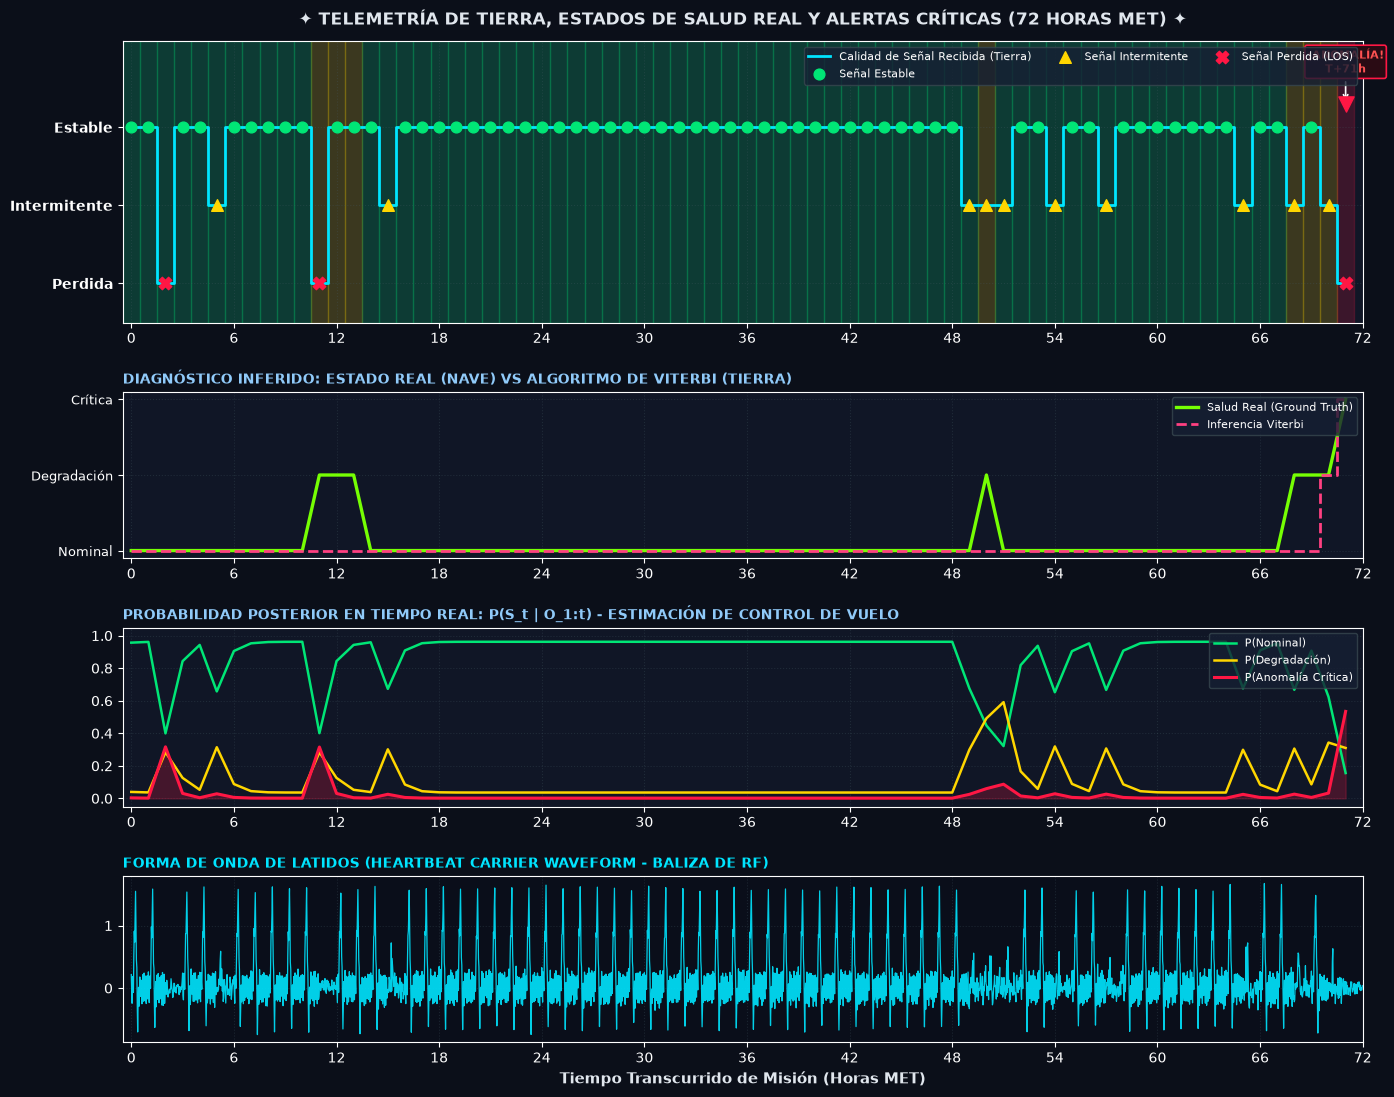

C:\Users\Administrador\AppData\Local\Temp\ipykernel_4732\3845267512.py:103: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


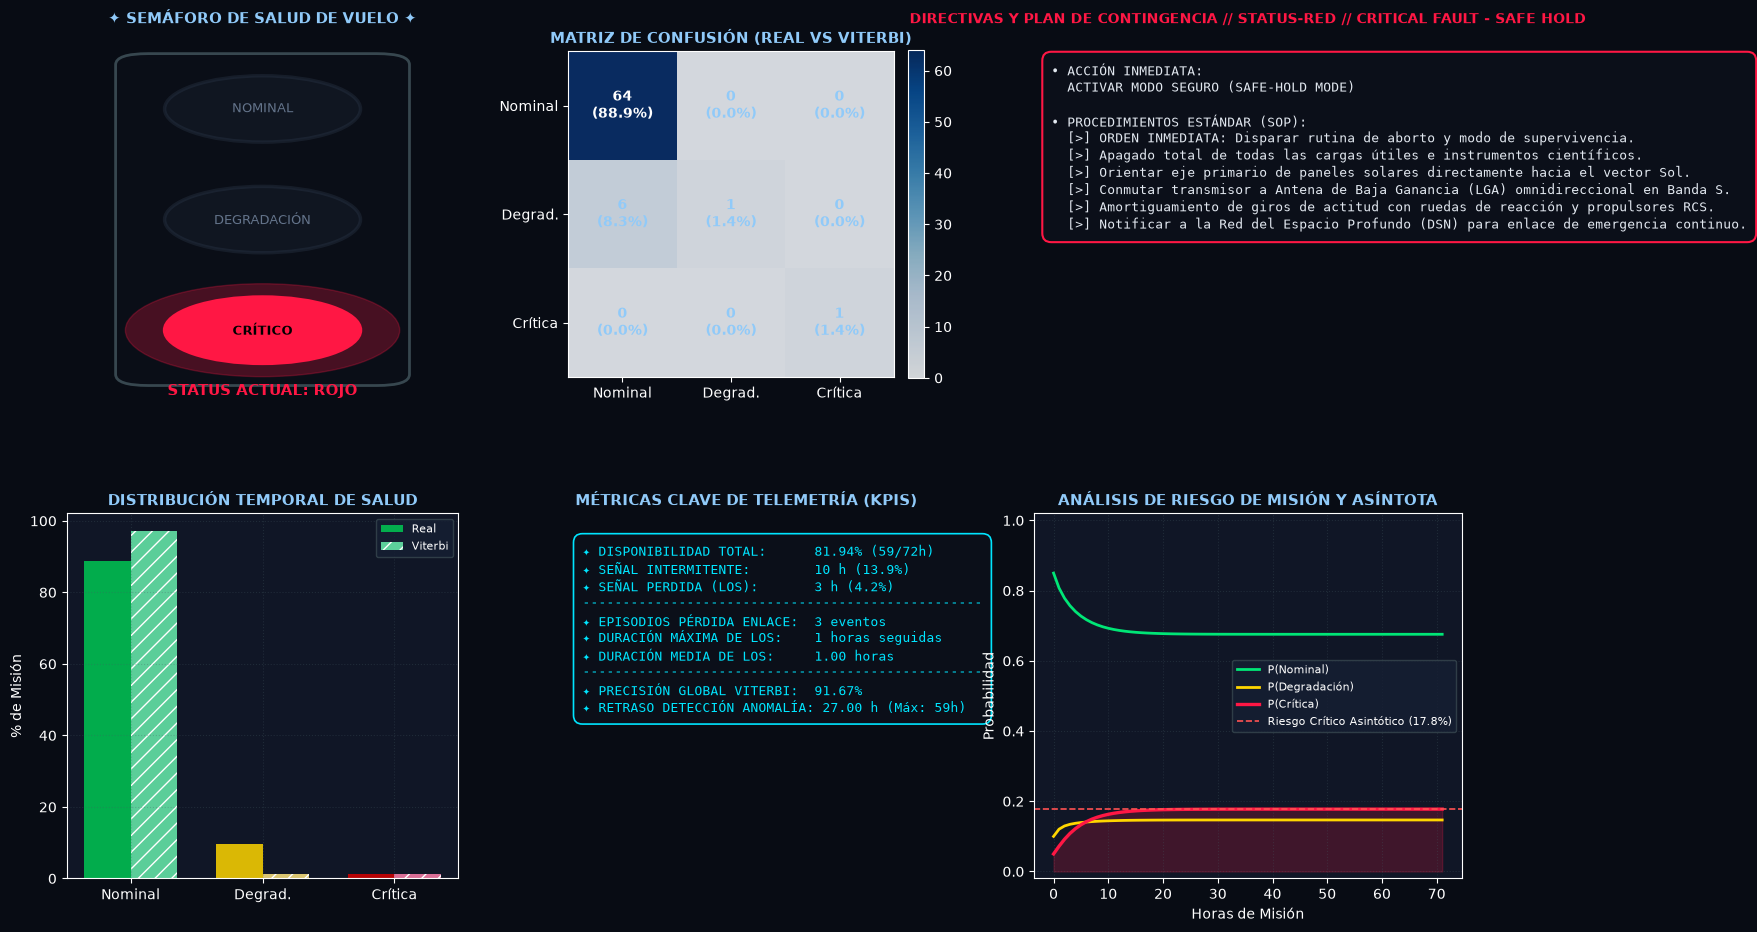

In [6]:
hmm = SpacecraftHMM()
real_states, observations = hmm.simulate(n_hours=72, seed=42)
viterbi_states, best_log_prob = hmm.viterbi(observations)
alpha_probs = hmm.forward_filtering(observations)
metrics = compute_mission_kpis(real_states, observations, viterbi_states)
steady_state = hmm.compute_steady_state()
risk_curve = hmm.risk_profile_projection(72)
current_state = viterbi_states[-1]

print(f"• Disponibilidad de Telemetría:       {metrics['availability_pct']:.2f}%")
print(f"• Precisión Global de Inferencia:     {metrics['accuracy']:.2f}%")
print(f"• Retraso Promedio Detección Fallas:  {metrics['avg_detection_delay']:.2f} horas")
print(f"• Estado Final Detectado:             {CONTINGENCY_ACTIONS[current_state]['estado'].upper()}")

plot_timeline_and_heartbeat(real_states, observations, viterbi_states, alpha_probs)
plot_mission_dashboard(metrics, current_state, steady_state, risk_curve)

## 7. Visualización del Grafo de Markov con NetworkX
Genera el diagrama topológico de la máquina de estados y las emisiones estocásticas.

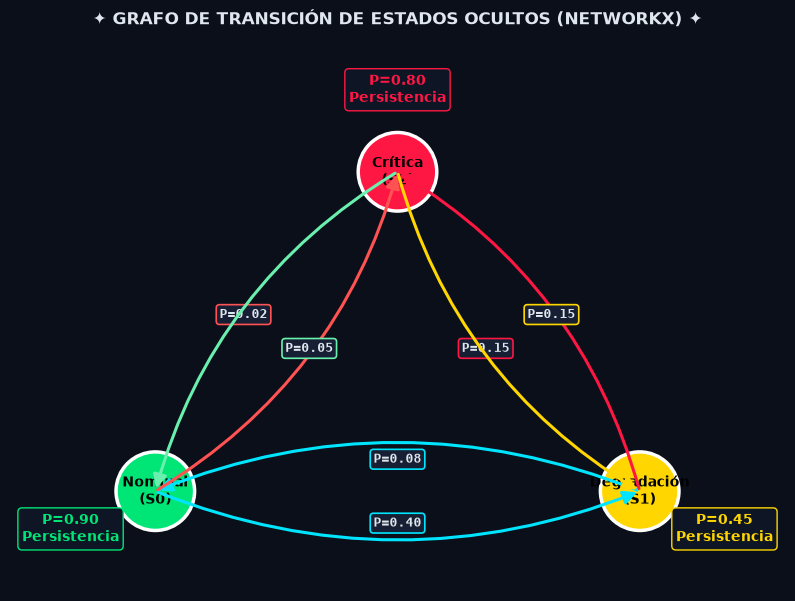

In [7]:
def plot_markov_graph(A):
    fig, ax = plt.subplots(figsize=(10, 7), facecolor='#0B0F19')
    ax.set_facecolor('#0B0F19')
    G = nx.DiGraph()
    names = ['Nominal\n(S0)', 'Degradación\n(S1)', 'Crítica\n(S2)']
    colors = ['#00E676', '#FFD600', '#FF1744']
    pos = {0: np.array([-1.0, -0.6]), 1: np.array([1.0, -0.6]), 2: np.array([0.0, 1.0])}

    for i in range(3): G.add_node(i, label=names[i])
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=3200, edgecolors='#FFFFFF', linewidths=2.5)
    nx.draw_networkx_labels(G, pos, {i: names[i] for i in range(3)}, ax=ax, font_size=10, font_weight='bold', font_color='#000000')

    edges = [(0, 1, 0.20, '#00E5FF'), (1, 0, 0.20, '#00E5FF'), (0, 2, 0.20, '#FF5252'), 
             (2, 0, 0.20, '#69F0AE'), (1, 2, 0.20, '#FF1744'), (2, 1, 0.20, '#FFD600')]
    for u, v, rad, col in edges:
        ax.annotate("", xy=pos[v], xycoords='data', xytext=pos[u], textcoords='data',
                    arrowprops=dict(arrowstyle="-|>", connectionstyle=f"arc3,rad={rad}", color=col, lw=2.2, mutation_scale=20))
        mid_x = (pos[u][0] + pos[v][0])/2.0; mid_y = (pos[u][1] + pos[v][1])/2.0
        dx = pos[v][0] - pos[u][0]; dy = pos[v][1] - pos[u][1]; norm = np.hypot(dx, dy)
        ax.text(mid_x - dy/norm*rad*0.8, mid_y + dx/norm*rad*0.8, f"P={A[u,v]:.2f}",
                color='#E0E6ED', fontsize=9.5, fontweight='bold', fontfamily='monospace', ha='center', va='center',
                bbox=dict(boxstyle="round,pad=0.25", fc="#161F33", ec=col, lw=1.2))

    # Bucles de persistencia
    ax.text(-1.35, -0.85, f"P={A[0,0]:.2f}\nPersistencia", color='#00E676', fontweight='bold', ha='center', bbox=dict(boxstyle="round", fc="#0E1626", ec="#00E676"))
    ax.text(1.35, -0.85, f"P={A[1,1]:.2f}\nPersistencia", color='#FFD600', fontweight='bold', ha='center', bbox=dict(boxstyle="round", fc="#0E1626", ec="#FFD600"))
    ax.text(0.0, 1.35, f"P={A[2,2]:.2f}\nPersistencia", color='#FF1744', fontweight='bold', ha='center', bbox=dict(boxstyle="round", fc="#0E1626", ec="#FF1744"))

    ax.set_title("✦ GRAFO DE TRANSICIÓN DE ESTADOS OCULTOS (NETWORKX) ✦", fontsize=12, fontweight='bold', color='#E0E6ED', pad=20)
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.1, 1.6); ax.axis('off')
    plt.show()

plot_markov_graph(hmm.A)

## 8. Simulación Masiva Monte Carlo ($N = 10{,}000$ Misiones)
Calcula la Curva de Supervivencia de Misión $R(t)$ y el tiempo medio hasta la primera falla crítica (MTTF).

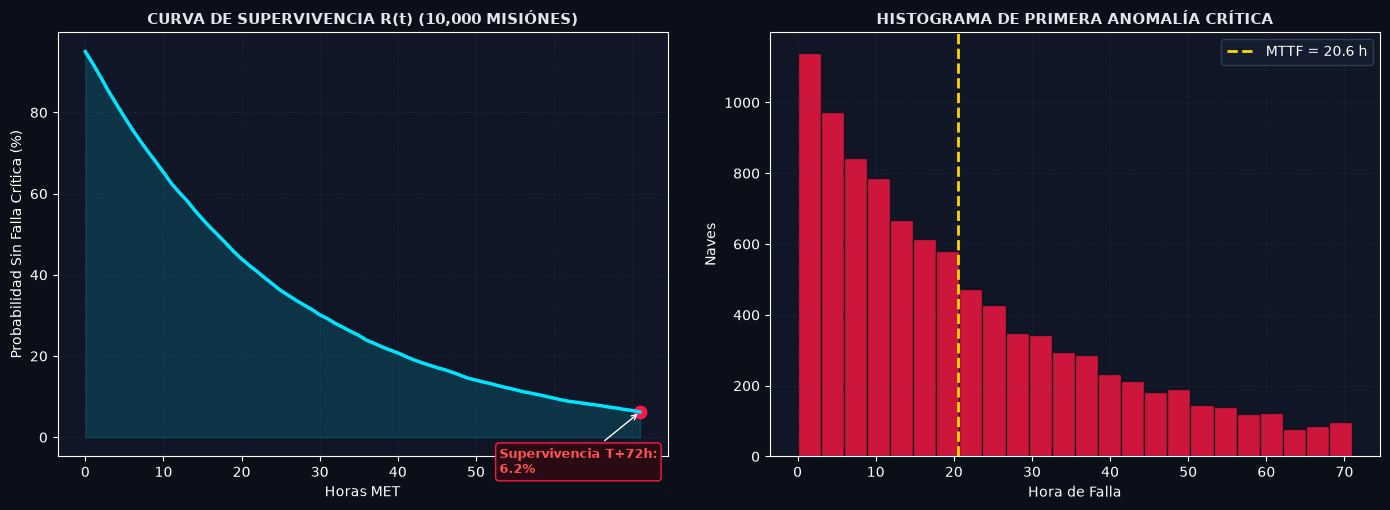

• MTTF Promedio: 20.60 horas
• Tasa de naves con anomalía crítica en 72h: 93.79%


In [8]:
def run_monte_carlo(n_missions=10000, n_hours=72, seed=42):
    rng = np.random.default_rng(seed)
    A_cdf = np.cumsum(hmm.A, axis=1)
    pi_cdf = np.cumsum(hmm.pi)
    states = np.zeros((n_missions, n_hours), dtype=np.int8)

    states[:, 0] = np.digitize(rng.uniform(0, 1, size=n_missions), pi_cdf)
    for t in range(1, n_hours):
        cdfs = A_cdf[states[:, t - 1]]
        u = rng.uniform(0, 1, size=n_missions)
        states[:, t] = (u[:, None] > cdfs).sum(axis=1)

    # Primer instante con anomalía crítica (estado 2)
    first_failure = np.full(n_missions, n_hours + 1)
    has_failed = (states == 2)
    for i in range(n_missions):
        idx = np.where(has_failed[i])[0]
        if len(idx) > 0: first_failure[i] = idx[0]

    hours = np.arange(n_hours)
    R = np.array([np.mean(first_failure > t) for t in hours]) * 100
    failed_mask = first_failure <= n_hours
    mttf = float(np.mean(first_failure[failed_mask])) if np.any(failed_mask) else float(n_hours)
    
    # Gráfico de Confiabilidad
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), facecolor='#0B0F19')
    ax1.set_facecolor('#101626'); ax2.set_facecolor('#101626')
    
    ax1.plot(hours, R, color='#00E5FF', lw=2.5, label='Confiabilidad R(t)')
    ax1.fill_between(hours, 0, R, color='#00E5FF', alpha=0.15)
    ax1.scatter(hours[-1], R[-1], color='#FF1744', s=80)
    ax1.annotate(f"Supervivencia T+72h:\n{R[-1]:.1f}%", xy=(hours[-1], R[-1]), xytext=(hours[-1]-18, R[-1]-15),
                 arrowprops=dict(facecolor='#FF1744', arrowstyle="->"), fontsize=9, fontweight='bold', color='#FF5252',
                 bbox=dict(boxstyle="round", fc="#2A0B14", ec="#FF1744"))
    ax1.set_title(f"CURVA DE SUPERVIVENCIA R(t) ({n_missions:,} MISIÓNES)", fontsize=11, fontweight='bold', color='#E0E6ED')
    ax1.set_xlabel("Horas MET"); ax1.set_ylabel("Probabilidad Sin Falla Crítica (%)")
    ax1.grid(True, linestyle=':', alpha=0.3, color='#455A64')

    ax2.hist(first_failure[failed_mask], bins=24, color='#FF1744', alpha=0.8, edgecolor='#0B0F19')
    ax2.axvline(mttf, color='#FFD600', lw=2.0, linestyle='--', label=f"MTTF = {mttf:.1f} h")
    ax2.set_title("HISTOGRAMA DE PRIMERA ANOMALÍA CRÍTICA", fontsize=11, fontweight='bold', color='#E0E6ED')
    ax2.set_xlabel("Hora de Falla"); ax2.set_ylabel("Naves")
    ax2.legend(loc='upper right', facecolor='#161F33', edgecolor='#37474F')
    ax2.grid(True, linestyle=':', alpha=0.3, color='#455A64')
    plt.tight_layout()
    plt.show()

    print(f"• MTTF Promedio: {mttf:.2f} horas")
    print(f"• Tasa de naves con anomalía crítica en 72h: {np.mean(failed_mask)*100:.2f}%")

run_monte_carlo(10000)

## 9. Calibración no supervisada con Baum-Welch (EM)
Re-estima las matrices de transición $A$ y de emisión $B$ a partir de telemetría sin etiquetar.

In [11]:
import sys, os
sys.path.append(os.path.abspath('..'))

# Si la ruta local no está disponible, usa la clase embebida auto-contenida:
try:
    from src.baum_welch import BaumWelchTrainer
except ModuleNotFoundError:
    class BaumWelchTrainer:
        def __init__(self, n_states=3, n_obs=3, max_iter=25, tol=1e-4):
            self.n_states, self.n_obs, self.max_iter, self.tol = n_states, n_obs, max_iter, tol
        def fit(self, observations_list, init_A=None, init_B=None, init_pi=None):
            K, M = self.n_states, self.n_obs
            rng = np.random.default_rng(123)
            A = np.copy(init_A) if init_A is not None else rng.uniform(0.1, 1.0, (K, K))
            A /= A.sum(axis=1, keepdims=True)
            B = np.copy(init_B) if init_B is not None else rng.uniform(0.1, 1.0, (K, M))
            B /= B.sum(axis=1, keepdims=True)
            pi = np.copy(init_pi) if init_pi is not None else np.ones(K)/K
            for iteration in range(self.max_iter):
                exp_trans, exp_emiss, exp_init = np.zeros((K, K)), np.zeros((K, M)), np.zeros(K)
                for obs in observations_list:
                    T = len(obs)
                    alpha, c = np.zeros((T, K)), np.zeros(T)
                    raw = pi * B[:, obs[0]]; c[0] = 1.0 / (np.sum(raw) + 1e-16); alpha[0] = raw * c[0]
                    for t in range(1, T):
                        raw = (alpha[t-1] @ A) * B[:, obs[t]]
                        c[t] = 1.0 / (np.sum(raw) + 1e-16); alpha[t] = raw * c[t]
                    beta = np.zeros((T, K)); beta[T-1] = c[T-1]
                    for t in range(T-2, -1, -1):
                        beta[t] = (A @ (B[:, obs[t+1]] * beta[t+1])) * c[t]
                    gamma = (alpha * beta) / ((alpha * beta).sum(axis=1, keepdims=True) + 1e-16)
                    xi = np.zeros((T-1, K, K))
                    for t in range(T-1):
                        num = alpha[t, :, None] * A * B[None, :, obs[t+1]] * beta[t+1, None, :]
                        xi[t] = num / (np.sum(num) + 1e-16)
                    exp_init += gamma[0]; exp_trans += xi.sum(axis=0)
                    for t in range(T): exp_emiss[:, obs[t]] += gamma[t]
                A_new = exp_trans / (exp_trans.sum(axis=1, keepdims=True) + 1e-16)
                B_new = exp_emiss / (exp_emiss.sum(axis=1, keepdims=True) + 1e-16)
                pi_new = exp_init / (np.sum(exp_init) + 1e-16)
                if np.max(np.abs(A - A_new)) < self.tol: break
                A, B, pi = A_new, B_new, pi_new
            return {'A_learned': A, 'B_learned': B, 'pi_learned': pi, 'iterations': iteration + 1}

# Generar datos de telemetría de 15 pases orbitales (1,080 horas)
dataset = [hmm.simulate(n_hours=72, seed=i+100)[1] for i in range(15)]

# Suposición inicial ruidosa (sin calibrar)
noisy_A = np.array([
    [0.75, 0.15, 0.10],
    [0.25, 0.50, 0.25],
    [0.10, 0.20, 0.70]
])

trainer = BaumWelchTrainer(n_states=3, n_obs=3, max_iter=25)
fit_res = trainer.fit(dataset, init_A=noisy_A)

print("✓ Algoritmo Baum-Welch convergido en:", fit_res["iterations"], "iteraciones")
print("\nMatriz A Real:")
print(hmm.A)
print("\nMatriz A Calibrada por Baum-Welch (a partir de telemetría cruda):")
print(np.round(fit_res["A_learned"], 3))

✓ Algoritmo Baum-Welch convergido en: 25 iteraciones

Matriz A Real:
[[0.9  0.08 0.02]
 [0.4  0.45 0.15]
 [0.05 0.15 0.8 ]]

Matriz A Calibrada por Baum-Welch (a partir de telemetría cruda):
[[0.924 0.027 0.049]
 [0.076 0.822 0.102]
 [0.25  0.227 0.523]]


## 10. Monitor de Telemetría en Streaming (Detección en Tiempo Real)

In [10]:
import sys, os
sys.path.append(os.path.abspath('..'))

try:
    from src.telemetry_stream import TelemetryStreamMonitor
except ModuleNotFoundError:
    class TelemetryStreamMonitor:
        STATE_NAMES = ['Operación Nominal', 'Degradación de Sistemas', 'Anomalía Crítica']
        STATE_COLORS = ['VERDE', 'AMARILLO', 'ROJO']
        OBS_NAMES = ['Señal Estable', 'Señal Intermitente', 'Señal Perdida']
        def __init__(self, A=None, B=None, pi=None):
            self.A = np.array(A if A is not None else [[0.90, 0.08, 0.02], [0.40, 0.45, 0.15], [0.05, 0.15, 0.80]])
            self.B = np.array(B if B is not None else [[0.85, 0.12, 0.03], [0.30, 0.50, 0.20], [0.05, 0.15, 0.80]])
            self.pi = np.array(pi if pi is not None else [0.85, 0.10, 0.05])
            self.current_hour = 0
            self.belief = self.pi.copy()
        def ingest_packet(self, obs):
            if self.current_hour == 0:
                raw = self.pi * self.B[:, obs]
            else:
                raw = (self.belief @ self.A) * self.B[:, obs]
            self.belief = raw / (np.sum(raw) + 1e-16)
            st = int(np.argmax(self.belief))
            actions = {
                0: "Continuar operaciones nominales de ciencia y descarga.",
                1: "ALERTA AMARILLA: Monitoreo intensivo a 1Hz. Suspender ciencia secundaria.",
                2: "¡EMERGENCIA ROJA! ACTIVAR MODO SEGURO (SAFE-HOLD MODE) INMEDIATO."
            }
            res = {
                "hour": self.current_hour,
                "obs_received": self.OBS_NAMES[obs],
                "status_color": self.STATE_COLORS[st],
                "confidence": float(self.belief[st]) * 100.0,
                "action": actions[st]
            }
            self.current_hour += 1
            return res

stream = TelemetryStreamMonitor()
flujo_test = [0, 0, 0, 1, 1, 2, 2, 2]

print("Procesando paquetes de telemetría en streaming:")
print("-" * 85)
for obs_packet in flujo_test:
    rep = stream.ingest_packet(obs_packet)
    badge = f"[{rep['status_color']}]"
    print(f"MET T+{rep['hour']:02d}h | Señal: {rep['obs_received']:<18} | Estado: {badge:<10} ({rep['confidence']:.1f}%) | {rep['action']}")
print("-" * 85)

Procesando paquetes de telemetría en streaming:
-------------------------------------------------------------------------------------
MET T+00h | Señal: Señal Estable      | Estado: [VERDE]    (95.7%) | Continuar operaciones nominales de ciencia y descarga.
MET T+01h | Señal: Señal Estable      | Estado: [VERDE]    (96.1%) | Continuar operaciones nominales de ciencia y descarga.
MET T+02h | Señal: Señal Estable      | Estado: [VERDE]    (96.2%) | Continuar operaciones nominales de ciencia y descarga.
MET T+03h | Señal: Señal Intermitente | Estado: [VERDE]    (67.6%) | Continuar operaciones nominales de ciencia y descarga.
MET T+04h | Señal: Señal Intermitente | Estado: [AMARILLO] (49.2%) | ALERTA AMARILLA: Monitoreo intensivo a 1Hz. Suspender ciencia secundaria.
MET T+05h | Señal: Señal Perdida      | Estado: [ROJO]     (59.5%) | ¡EMERGENCIA ROJA! ACTIVAR MODO SEGURO (SAFE-HOLD MODE) INMEDIATO.
MET T+06h | Señal: Señal Perdida      | Estado: [ROJO]     (88.6%) | ¡EMERGENCIA ROJA! ACTIV